# Modelos de prioridad

Este notebook compara varias configuraciones de clasificadores sobre el mismo problema: predecir la prioridad de recolección de cada tramo.

**Repaso del reparto de datos.** El 60 % de las filas se usa solo para entrenar. El 20 % de *decisión* es el conjunto donde se mide cada configuración (F1 macro). El 20 % de *test* queda guardado y **no se usa aquí**: no entrenamos con él ni miramos métricas en este archivo.

El procedimiento es el mismo que en `tramos.ipynb`. La tabla final **no declara un ganador**; solo muestra resultados en el 20 % de decisión.


## Carga del CSV

Leemos `data/processed/tramos.csv`. Es una copia en memoria: **no** modificamos el archivo en disco.

Cuando aparece `head()`, muestra las **primeras cinco filas** como vista rápida. El dataset sigue teniendo todas las filas (1257 en total); no se borra el resto.


In [13]:
from pathlib import Path

import pandas as pd

ROOT = Path.cwd()
if not (ROOT / "data" / "processed" / "tramos.csv").exists():
    ROOT = ROOT.parent

CSV = ROOT / "data" / "processed" / "tramos.csv"
tramos = pd.read_csv(CSV)
tramos.shape


(1257, 13)

## Target y features

**Variable a predecir (y):** `prioridad_recoleccion` (alta, media o baja).

**Entradas del modelo (X):**
- `dias_desde_ultima_recoleccion`
- `cantidad_contenedores`
- `historico_quejas_vecinales`
- `cerca_escuela_hospital`
- `feria_o_evento`
- `tipo_zona`

Columnas que **no** entran como features: identificadores y datos de calle (`tramo_id`, `u`, `v`, `nombre_calle`, `distancia_m`, `highway`).


In [ ]:
TARGET = "prioridad_recoleccion"
FEATURES = [
    "dias_desde_ultima_recoleccion",
    "cantidad_contenedores",
    "historico_quejas_vecinales",
    "cerca_escuela_hospital",
    "feria_o_evento",
    "tipo_zona",
]
NUMERIC = FEATURES[:4]

y = tramos[TARGET]
X = tramos[FEATURES].copy()
pd.concat([y.rename(TARGET), X], axis=1).head()


,prioridad_recoleccion,dias_desde_ultima_recoleccion,cantidad_contenedores,historico_quejas_vecinales,cerca_escuela_hospital,feria_o_evento,tipo_zona
0,media,4,0,2,0,0,residencial
1,media,4,0,1,1,0,residencial
2,media,5,0,1,1,0,residencial
3,baja,1,0,0,0,0,residencial
4,alta,7,0,0,0,0,residencial


## Nulos

**No** eliminamos filas por valores faltantes y **no** rellenamos (imputamos) ningún hueco.

`isna().sum()` cuenta cuántos NaN hay por columna. En este CSV el resultado es **0** en todas: no hay nada que completar.

El `raise` en el código es una red de seguridad: si apareciera un NaN, el notebook se detiene antes de entrenar, para no entrenar con un hueco sin haber decidido qué hacer. Con los datos actuales, ese caso no ocurre.


In [3]:
nulls = X.isna().sum()
if nulls.any():
    raise ValueError(f"Hay nulos en features; no se imputa:\n{nulls[nulls > 0]}")
nulls


dias_desde_ultima_recoleccion    0
cantidad_contenedores            0
historico_quejas_vecinales       0
cerca_escuela_hospital           0
feria_o_evento                   0
tipo_zona                        0
dtype: int64

## Split 60 / 20 / 20

Partimos las 1257 filas en tres grupos: 60 % para entrenar (754), 20 % para decidir (251) y 20 % de test (252). El procedimiento es el de `notebooks/tramos.ipynb`:

1. Primera partición: 60 % entrenamiento y 40 % resto (`test_size=0.40`, `random_state=42`, `stratify` por la prioridad).
2. Segunda partición sobre el resto: mitad y mitad, 20 % decisión y 20 % test (`test_size=0.50`, mismos `random_state` y `stratify`).

El corte sí es 60/20/20 en cantidad de filas. Lo que evita un reparto injusto de las clases es `stratify`. Mira la prioridad (alta, media, baja) y deja en cada grupo más o menos la misma proporción. Así no puede pasar que casi todas las prioridades altas caigan en el test y el entrenamiento no las vea.

Eso no reparte parejo las columnas, por ejemplo las quejas o los contenedores. Solo equilibra la clase que queremos predecir. Una columna puede quedar un poco más cargada en un grupo por azar.

`random_state=42` no equilibra nada. Solo fija el azar: cada vez que se corre el notebook, las mismas filas caen en el mismo grupo.

El 20 % de test no se usa para entrenar ni para la tabla de F1.


In [4]:
from sklearn.model_selection import train_test_split

X_train, X_rest, y_train, y_rest = train_test_split(
    X,
    y,
    test_size=0.40,
    random_state=42,
    stratify=y,
)
X_decision, X_test_hold, y_decision, y_test_hold = train_test_split(
    X_rest,
    y_rest,
    test_size=0.50,
    random_state=42,
    stratify=y_rest,
)

n_train = len(X_train)
n_decision = len(X_decision)
n_test = len(X_test_hold)
pd.DataFrame(
    {
        "conjunto": ["train (60 %)", "decisión (20 %)", "test holdout (20 %)"],
        "n": [n_train, n_decision, n_test],
    }
)


,conjunto,n
0,train (60 %),754
1,decisión (20 %),251
2,test holdout (20 %),252


## Matrices y entrenamiento

`tipo_zona` se convierte en columnas dummy con `pd.get_dummies`, usando **solo** las categorías vistas en el 60 % de train; en decisión se alinea con `reindex(..., fill_value=0)`.

Las cinco variables numéricas se escalan con `StandardScaler` ajustado **solo** en train y aplicado en decisión. Logística, kNN y SVM usan esa matriz escalada. Árbol y bosque usan numéricas sin escalar más los mismos dummies.

**Cómo se arma la tabla de abajo:** cada modelo se entrena **únicamente** con el 60 %. Luego predice el 20 % de decisión. El número de la tabla es `f1_score(y_decision, prediccion, average="macro")`. El test no entra. **No** es validación cruzada: una sola partición fija.


In [5]:
import warnings

import numpy as np
from sklearn.ensemble import RandomForestClassifier
from sklearn.exceptions import ConvergenceWarning
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import f1_score
from sklearn.neighbors import KNeighborsClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier


def train_decision_matrices(X_tr: pd.DataFrame, X_dec: pd.DataFrame):
    dummy_cols = list(
        pd.get_dummies(X_tr["tipo_zona"], prefix="tipo_zona", dtype=float).columns
    )

    def build(df: pd.DataFrame, scaler: StandardScaler | None) -> np.ndarray:
        num = df[NUMERIC].astype(float)
        if scaler is not None:
            num = pd.DataFrame(
                scaler.transform(num), columns=NUMERIC, index=df.index
            )
        dummies = pd.get_dummies(df["tipo_zona"], prefix="tipo_zona", dtype=float)
        dummies = dummies.reindex(columns=dummy_cols, fill_value=0.0)
        return pd.concat([num, dummies], axis=1).to_numpy()

    scaler = StandardScaler()
    scaler.fit(X_tr[NUMERIC].astype(float))
    return (
        build(X_tr, scaler),
        build(X_dec, scaler),
        build(X_tr, None),
        build(X_dec, None),
    )


X_train_s, X_dec_s, X_train_t, X_dec_t = train_decision_matrices(X_train, X_decision)


def score_config(clf, use_scaled: bool) -> float:
    if use_scaled:
        X_tr_fit, X_dec_pred = X_train_s, X_dec_s
    else:
        X_tr_fit, X_dec_pred = X_train_t, X_dec_t
    clf.fit(X_tr_fit, y_train)
    pred = clf.predict(X_dec_pred)
    return float(f1_score(y_decision, pred, average="macro"))


rows: list[dict] = []

for max_depth in [2, 3, 4, 5, 8]:
    for min_samples_leaf in [1, 5, 10]:
        params = {"max_depth": max_depth, "min_samples_leaf": min_samples_leaf}
        f1 = score_config(
            DecisionTreeClassifier(
                max_depth=max_depth,
                min_samples_leaf=min_samples_leaf,
                random_state=0,
            ),
            use_scaled=False,
        )
        rows.append(
            {
                "modelo": "DecisionTreeClassifier",
                "params": params,
                "f1_macro": f1,
            }
        )

for k in range(1, 60, 2):
    f1 = score_config(KNeighborsClassifier(n_neighbors=k), use_scaled=True)
    rows.append(
        {
            "modelo": "KNeighborsClassifier",
            "params": {"n_neighbors": k},
            "f1_macro": f1,
        }
    )

for c_val in [0.01, 1, 100]:
    for kernel in ["linear", "rbf"]:
        f1 = score_config(SVC(C=c_val, kernel=kernel), use_scaled=True)
        rows.append(
            {
                "modelo": "SVC",
                "params": {"C": c_val, "kernel": kernel},
                "f1_macro": f1,
            }
        )

logistic_used_max_iter = False
with warnings.catch_warnings(record=True) as caught:
    warnings.simplefilter("always", ConvergenceWarning)
    log_clf = LogisticRegression()
    log_clf.fit(X_train_s, y_train)
    converged = not any(issubclass(w.category, ConvergenceWarning) for w in caught)
if not converged:
    logistic_used_max_iter = True
    log_clf = LogisticRegression(max_iter=5000)
    log_clf.fit(X_train_s, y_train)
log_pred = log_clf.predict(X_dec_s)
log_f1 = float(f1_score(y_decision, log_pred, average="macro"))
log_params = {"max_iter": 5000} if logistic_used_max_iter else {}
rows.append(
    {
        "modelo": "LogisticRegression",
        "params": log_params,
        "f1_macro": log_f1,
    }
)

rf_f1 = score_config(
    RandomForestClassifier(n_estimators=100, random_state=0),
    use_scaled=False,
)
rows.append(
    {
        "modelo": "RandomForestClassifier",
        "params": {"n_estimators": 100, "random_state": 0},
        "f1_macro": rf_f1,
    }
)


### Logística y `max_iter`

En el material de la cátedra aparece `LogisticRegression()` sin argumentos extra.

Si el optimizador no converge en train, el notebook vuelve a entrenar con `max_iter=5000`. El indicador `logistic_used_max_iter` (arriba en la salida) muestra si hizo falta ese segundo intento.


## Tabla decisión (F1 macro)

### Qué mide F1 en una clase

Para cada clase (alta, media, baja) se combinan **precisión** y **recall** con la media armónica:

- **Precisión:** de todos los tramos que el modelo etiquetó como esa clase, cuántos realmente lo eran.
- **Recall:** de todos los tramos que en verdad eran de esa clase, cuántos el modelo encontró.

Eso da un F1 por clase.

### Qué es F1 macro

Se calcula el F1 de alta, el de media y el de baja, y se **promedian los tres con el mismo peso**. La clase baja es la más frecuente (~45 % del dataset) pero **no pesa más** en macro que alta o media.

Por eso no usamos accuracy para elegir modelo: uno que casi siempre predice “baja” puede tener accuracy alta y aun así fallar en alta y media; el F1 macro lo penaliza.

### Cómo se obtuvo esta tabla

Cada fila es una configuración distinta. Entrenamiento solo con el **60 %**. Métrica solo en el **20 % de decisión** (`f1_score(..., average="macro")`). El **20 % test no se mira** en este notebook.

La tabla está **ordenada de mayor a menor F1 macro** en decisión, solo para leer más fácil. **No** implica que el primero sea “el elegido”: el test sigue guardado para un paso posterior.

Un valor en el piso: el SVC con `C=0.01` y kernel `rbf` ronda **0.207** — casi no detecta tramos de prioridad alta ni media.


In [12]:
def _params_short(p: dict) -> str:
    if not p:
        return ""
    return ", ".join(f"{k}={v}" for k, v in p.items())


tabla = pd.DataFrame(rows)
tabla["params"] = tabla["params"].map(_params_short)
tabla["f1_macro"] = tabla["f1_macro"].round(3)
tabla = tabla.sort_values("f1_macro", ascending=False, ignore_index=True)
tabla


,modelo,params,f1_macro
0,SVC,"C=1, kernel=rbf",0.855
1,LogisticRegression,,0.842
2,SVC,"C=100, kernel=linear",0.834
3,SVC,"C=1, kernel=linear",0.834
4,DecisionTreeClassifier,"max_depth=5, min_samples_leaf=1",0.820
5,DecisionTreeClassifier,"max_depth=5, min_samples_leaf=5",0.809
6,SVC,"C=100, kernel=rbf",0.807
7,DecisionTreeClassifier,"max_depth=8, min_samples_leaf=10",0.802
8,DecisionTreeClassifier,"max_depth=5, min_samples_leaf=10",0.802
9,SVC,"C=0.01, kernel=linear",0.801


## Comparación sesión 04 (datos 2D sintéticos)

La figura del final (formas tipo medialunas, círculos y manchas mezcladas) reproduce el ejercicio de la **sesión 04** sobre **datos de juguete en 2D**, no sobre `tramos.csv`.

Ahí se usa el protocolo de la cátedra: `train_test_split` 70/30, `random_state=0`, y se reporta accuracy en test.

**No es el test del TP.** El holdout del 20 % de tramos de este proyecto no interviene en esa comparación.


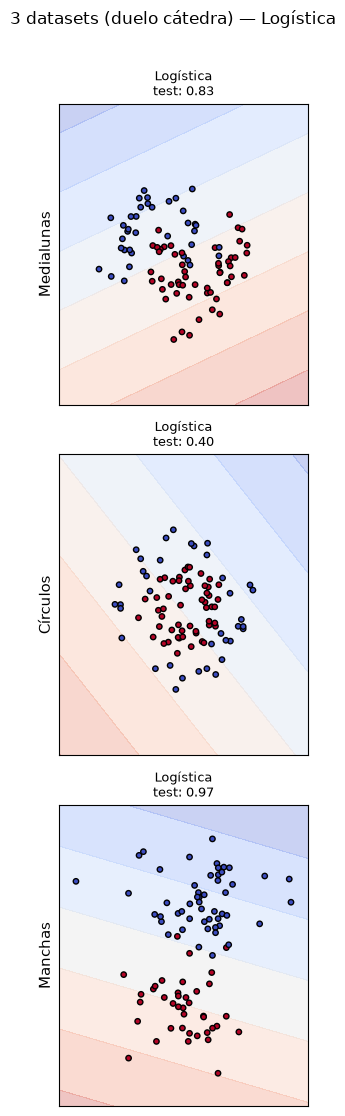

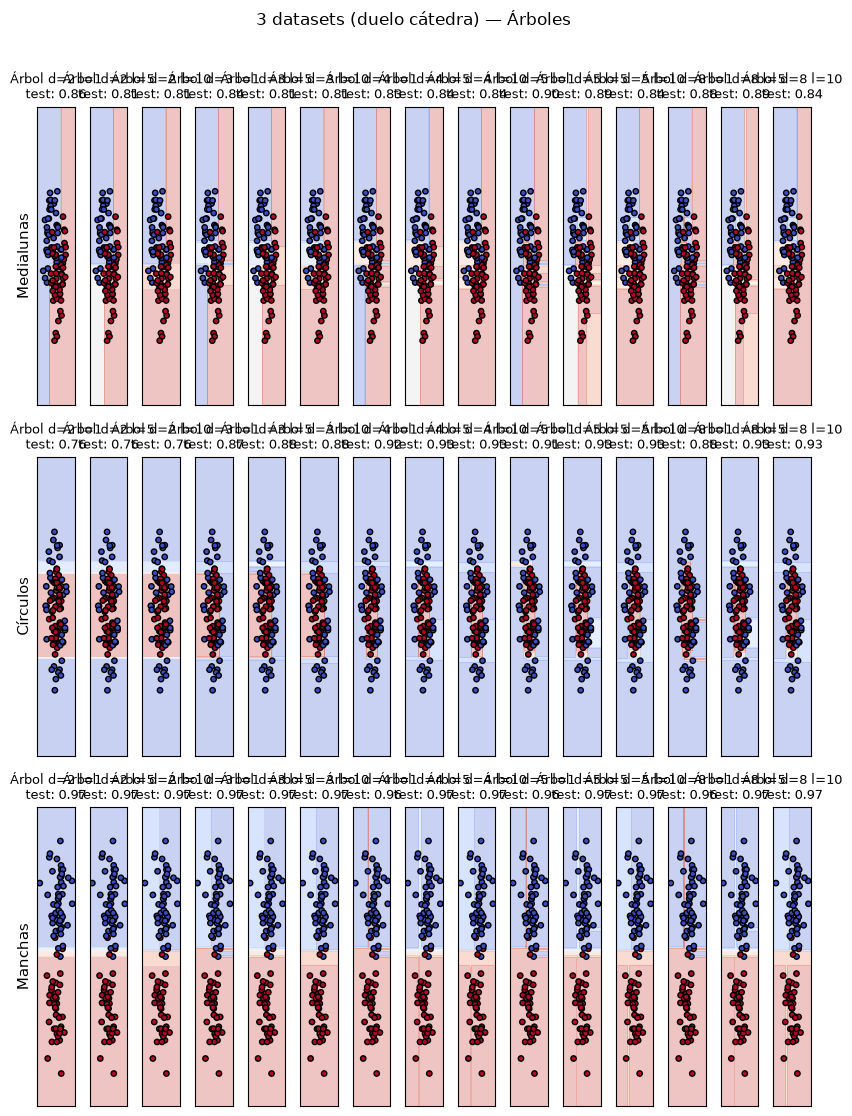

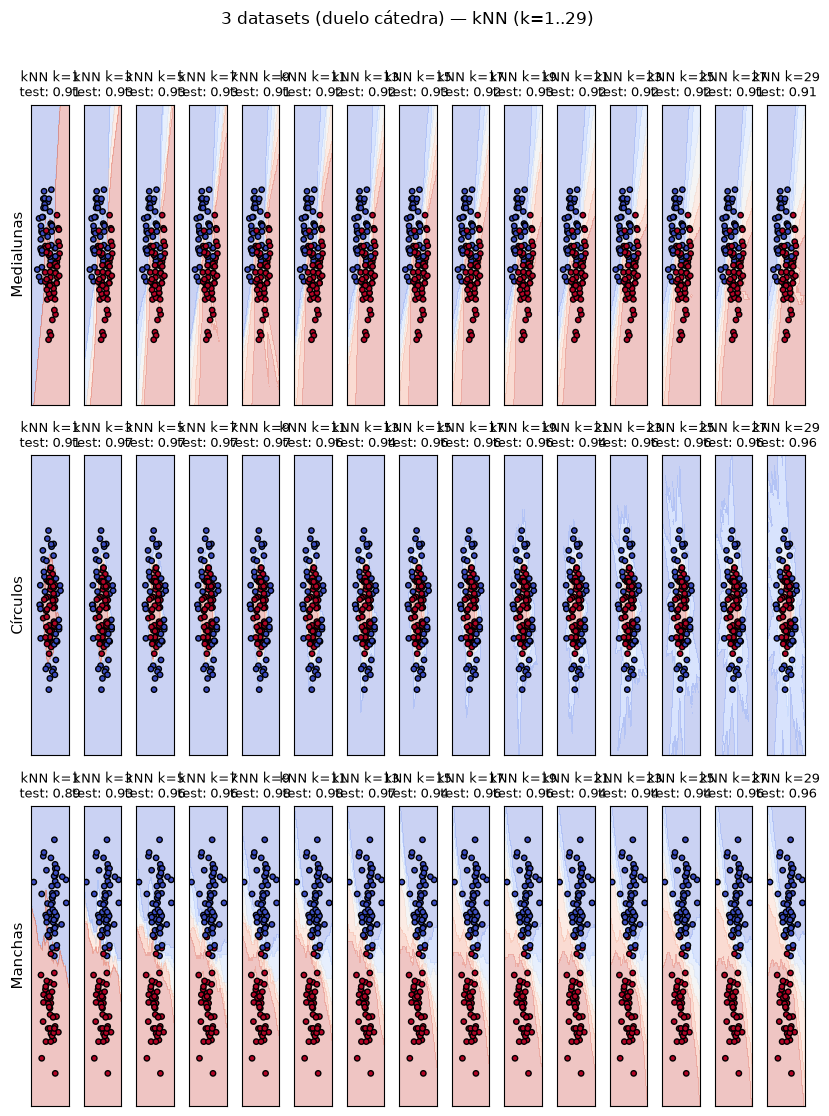

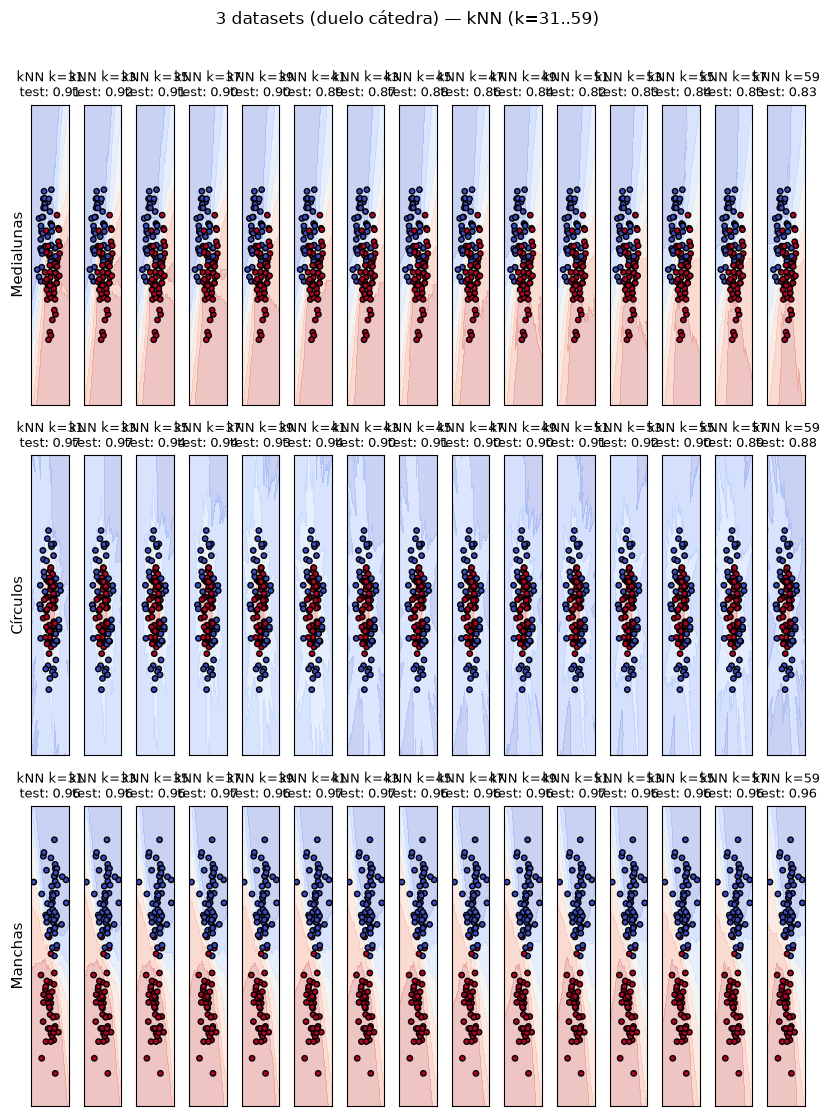

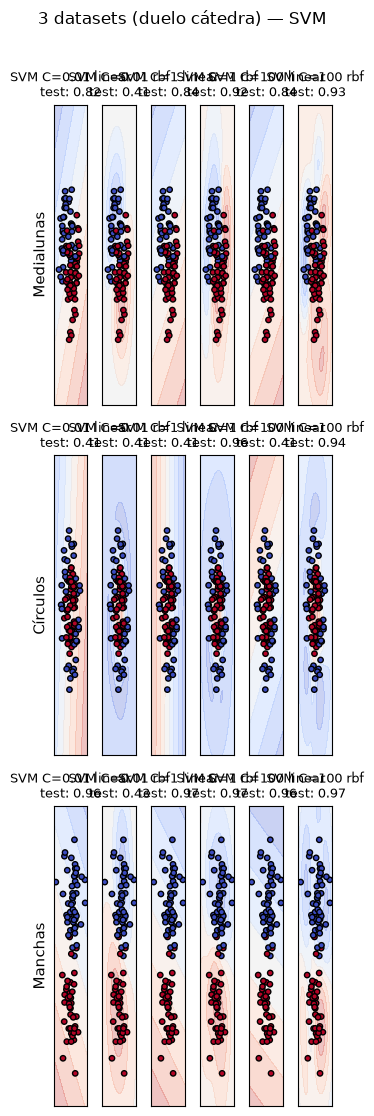

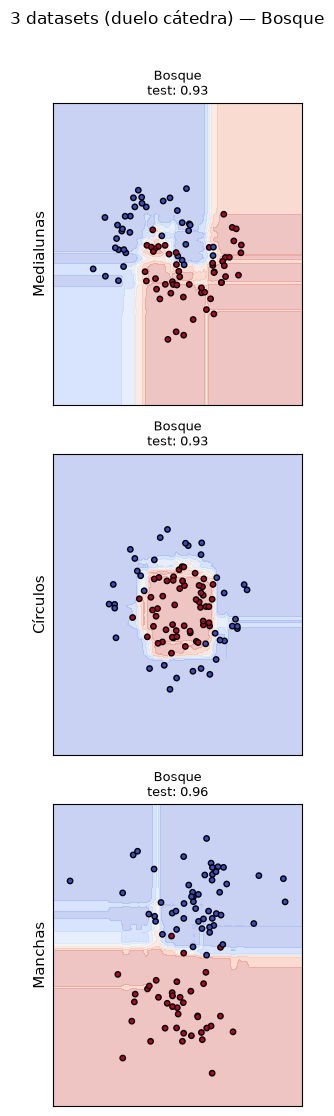

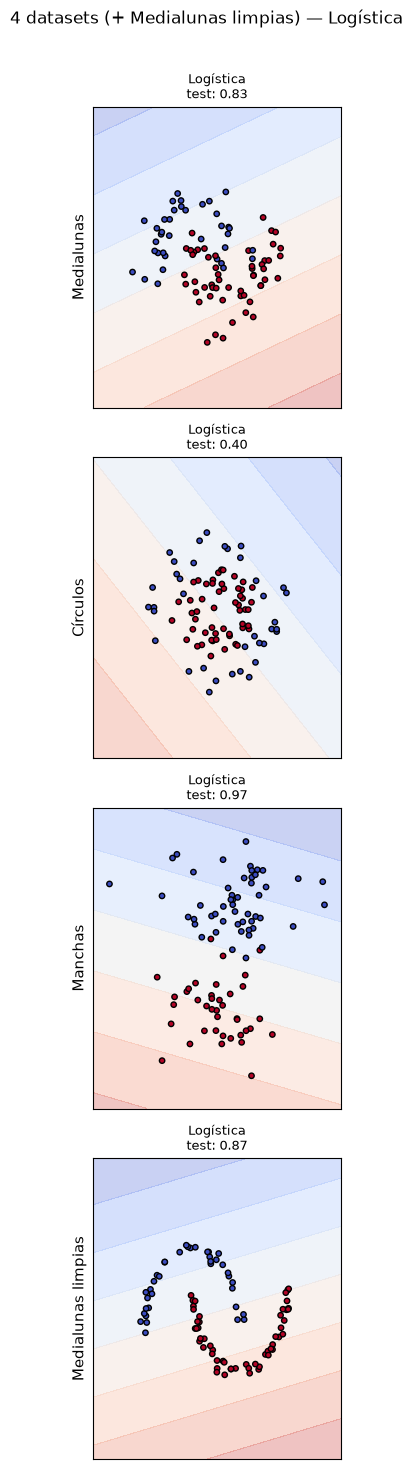

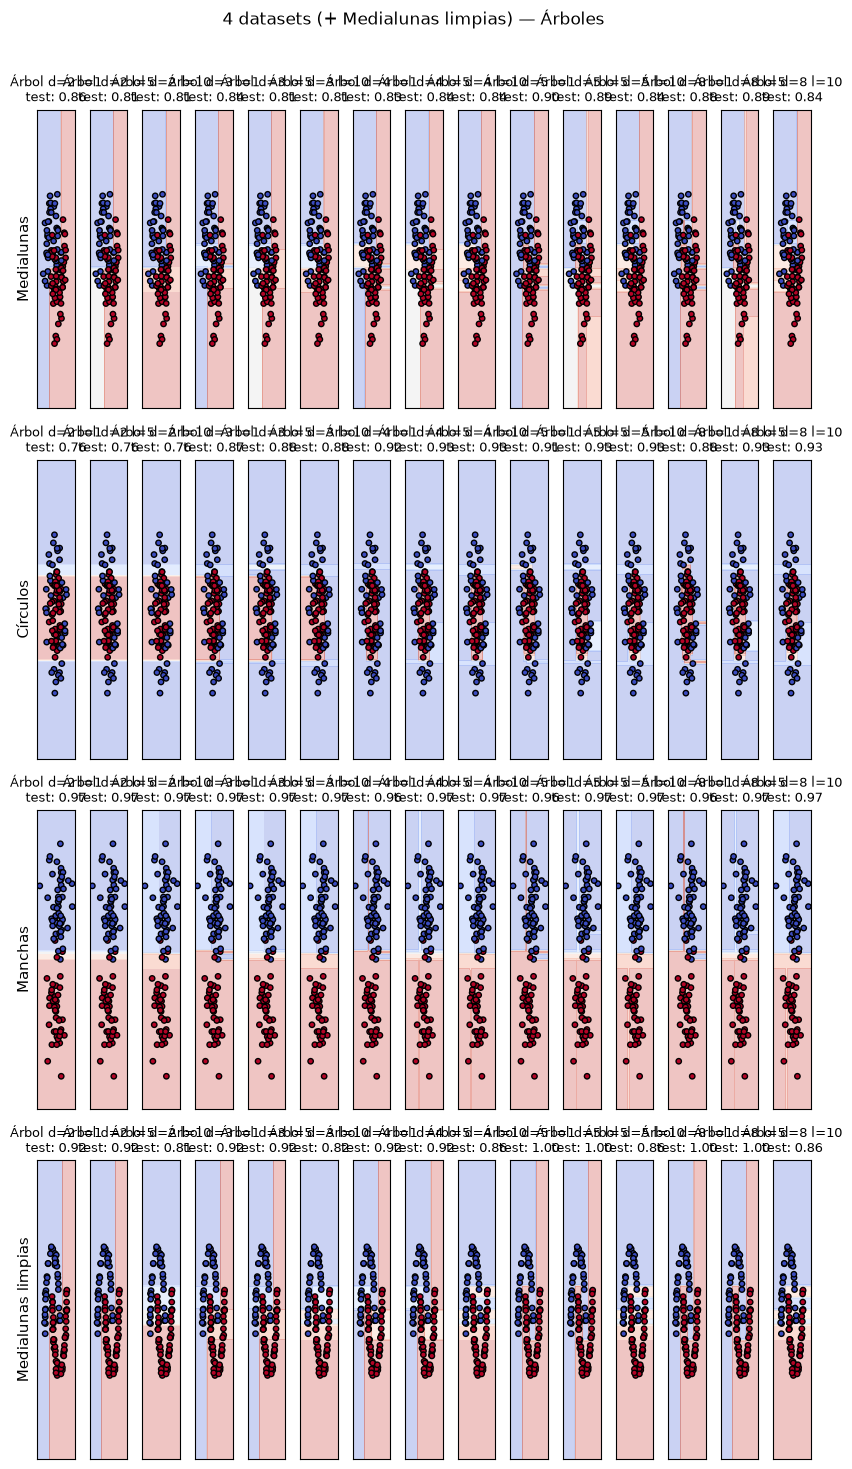

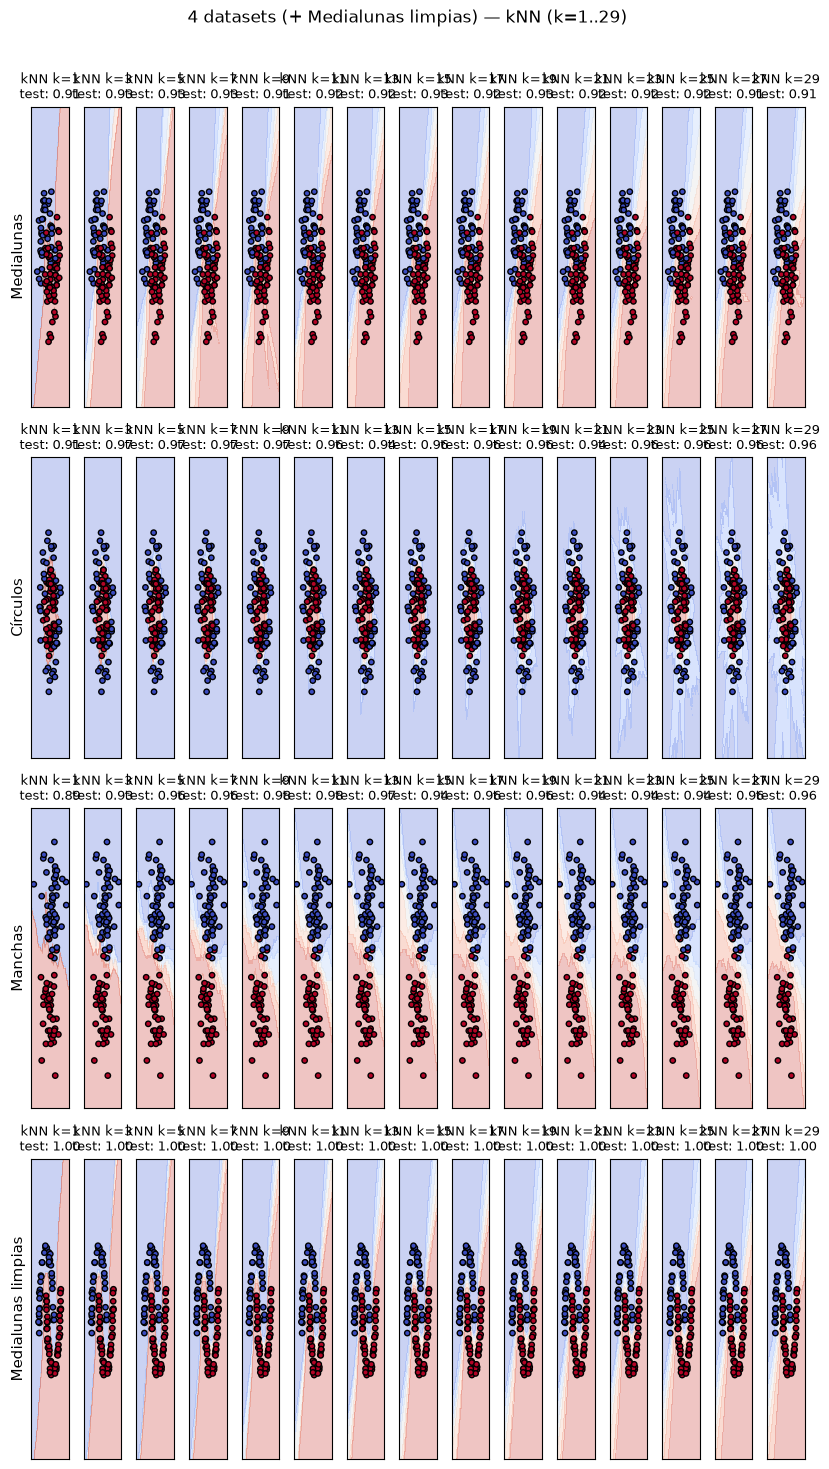

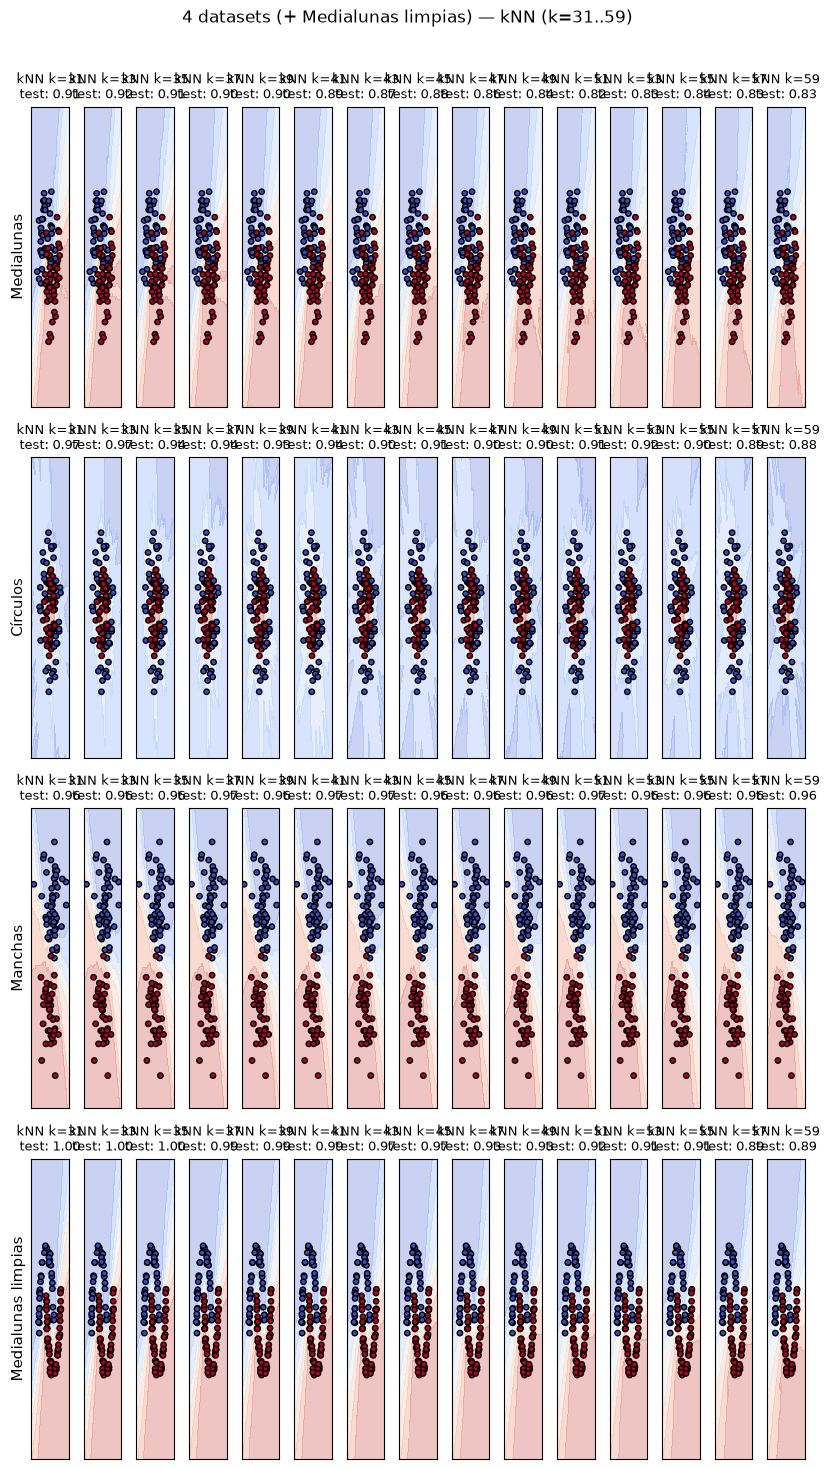

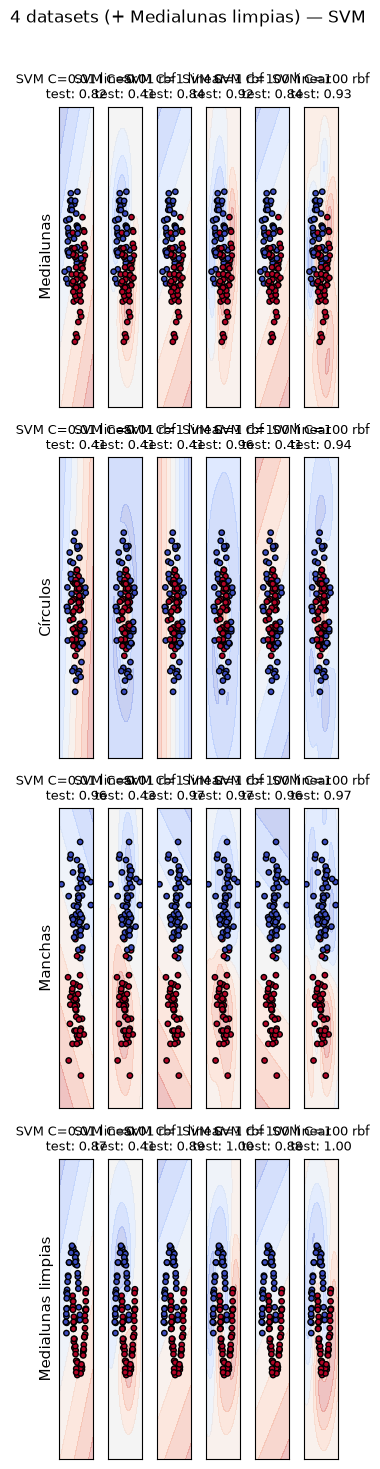

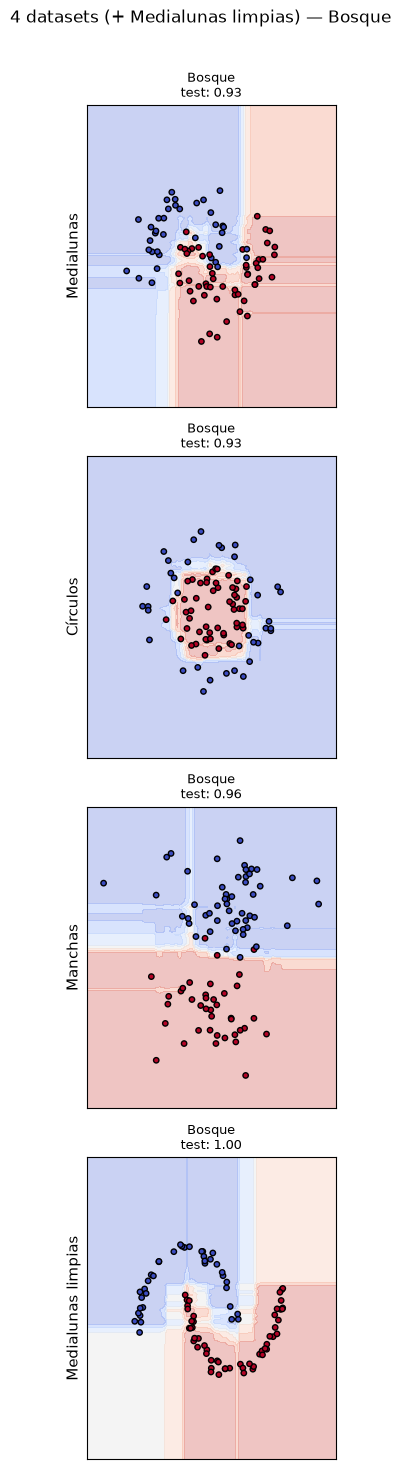

,Logística,Árbol d=2 l=1,Árbol d=2 l=5,Árbol d=2 l=10,Árbol d=3 l=1,Árbol d=3 l=5,Árbol d=3 l=10,Árbol d=4 l=1,Árbol d=4 l=5,Árbol d=4 l=10,...,kNN k=55,kNN k=57,kNN k=59,SVM C=0.01 linear,SVM C=0.01 rbf,SVM C=1 linear,SVM C=1 rbf,SVM C=100 linear,SVM C=100 rbf,Bosque
Medialunas,0.83,0.86,0.81,0.81,0.84,0.81,0.81,0.83,0.84,0.84,...,0.84,0.83,0.83,0.82,0.41,0.84,0.92,0.84,0.93,0.93
Círculos,0.40,0.76,0.76,0.76,0.87,0.88,0.88,0.92,0.93,0.93,...,0.90,0.89,0.88,0.41,0.41,0.41,0.96,0.41,0.94,0.93
Manchas,0.97,0.97,0.97,0.97,0.97,0.97,0.97,0.96,0.97,0.97,...,0.96,0.96,0.96,0.96,0.43,0.97,0.97,0.96,0.97,0.96
Medialunas limpias,0.87,0.92,0.92,0.81,0.92,0.92,0.82,0.92,0.92,0.86,...,0.91,0.89,0.89,0.87,0.41,0.89,1.00,0.88,1.00,1.00


In [7]:
import matplotlib.pyplot as plt
from sklearn.base import clone
from sklearn.datasets import make_blobs, make_circles, make_moons
from sklearn.ensemble import RandomForestClassifier
from sklearn.inspection import DecisionBoundaryDisplay
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier

DATASETS_3 = {
    "Medialunas": make_moons(n_samples=300, noise=0.3, random_state=0),
    "Círculos": make_circles(n_samples=300, factor=0.5, noise=0.15, random_state=0),
    "Manchas": make_blobs(n_samples=300, centers=2, cluster_std=2.0, random_state=6),
}

DATASETS_4 = {
    **DATASETS_3,
    "Medialunas limpias": make_moons(n_samples=300, noise=0.05, random_state=0),
}


def _modelos_tp():
    logistic = [
        ("Logística", make_pipeline(StandardScaler(), LogisticRegression())),
    ]
    trees = [
        (
            f"Árbol d={d} l={msl}",
            DecisionTreeClassifier(
                max_depth=d, min_samples_leaf=msl, random_state=0
            ),
        )
        for d in [2, 3, 4, 5, 8]
        for msl in [1, 5, 10]
    ]
    knn_all = [
        (
            f"kNN k={k}",
            make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=k)),
        )
        for k in range(1, 60, 2)
    ]
    svm = [
        (
            f"SVM C={c} {kernel}",
            make_pipeline(StandardScaler(), SVC(C=c, kernel=kernel)),
        )
        for c in [0.01, 1, 100]
        for kernel in ["linear", "rbf"]
    ]
    forest = [
        ("Bosque", RandomForestClassifier(n_estimators=100, random_state=0)),
    ]
    return {
        "Logística": logistic,
        "Árboles": trees,
        "kNN (k=1..29)": knn_all[:15],
        "kNN (k=31..59)": knn_all[15:],
        "SVM": svm,
        "Bosque": forest,
    }


FAMILIAS = _modelos_tp()
resultados_sesion04: dict[str, dict[str, float]] = {}


def _plot_grilla_familia(
    titulo_fig: str,
    model_list: list,
    datasets: dict,
    resultados: dict,
) -> None:
    n_filas = len(datasets)
    n_cols = len(model_list)
    ancho = max(3.0, n_cols * 0.55)
    alto = 11.0 if n_filas == 3 else 14.5
    fig, axes = plt.subplots(n_filas, n_cols, figsize=(ancho, alto))
    if n_filas == 1 and n_cols == 1:
        axes = [[axes]]
    elif n_filas == 1:
        axes = [axes]
    elif n_cols == 1:
        axes = [[ax] for ax in axes]

    for fila, (nombre_datos, (X, y)) in enumerate(datasets.items()):
        X_train, X_test, y_train, y_test = train_test_split(
            X, y, test_size=0.3, random_state=0
        )
        for col, (nombre_modelo, est_template) in enumerate(model_list):
            modelo = clone(est_template)
            modelo.fit(X_train, y_train)
            acc = modelo.score(X_test, y_test)
            resultados.setdefault(nombre_modelo, {})[nombre_datos] = round(acc, 2)

            ax = axes[fila][col]
            DecisionBoundaryDisplay.from_estimator(
                modelo, X, ax=ax, alpha=0.3, cmap="coolwarm"
            )
            ax.scatter(
                X_test[:, 0],
                X_test[:, 1],
                c=y_test,
                cmap="coolwarm",
                edgecolor="k",
                s=15,
            )
            ax.set_title(f"{nombre_modelo}\ntest: {acc:.2f}", fontsize=9)
            ax.set_xticks([])
            ax.set_yticks([])
            if col == 0:
                ax.set_ylabel(nombre_datos, fontsize=11)

    fig.suptitle(titulo_fig, fontsize=12, y=1.01)
    plt.tight_layout()
    plt.show()


def _correr_bloque(datasets: dict, etiqueta: str) -> None:
    for fam, model_list in FAMILIAS.items():
        _plot_grilla_familia(
            f"{etiqueta} — {fam}",
            model_list,
            datasets,
            resultados_sesion04,
        )


_correr_bloque(DATASETS_3, "3 datasets (duelo cátedra)")
_correr_bloque(DATASETS_4, "4 datasets (+ Medialunas limpias)")

pd.DataFrame(resultados_sesion04)
